# Notebook 03 – Mô hình hóa & Đánh giá dự báo (Modeling & Evaluation)

**Nội dung thực hiện:**
1. **Chia tập dữ liệu theo thời gian:** Đọc `clean_data.parquet`, chia Train (`< 2018-01-01`) và Test (`>= 2018-01-01`), không xáo trộn ngẫu nhiên, **sử dụng TimeSeriesSplit** để chia.
2. **Huấn luyện mô hình:** Thử nghiệm trên Bộ đặc trưng A (dài hạn) và Bộ đặc trưng B (ngắn hạn có biến trễ) với các mô hình: *Baseline (Seasonal Naive)*, *Ridge Regression*, *Random Forest*, *XGBoost*.
3. **Đánh giá & Phân tích lỗi:** Tính **MAE, RMSE, MAPE, $R^2$**, **F1**, **Recall**, **Presision**, trực quan hóa dự báo 7 ngày liên tiếp, phân tích sai số theo giờ/thời tiết và lưu model tốt nhất.

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

SEED = 42
TARGET = "traffic_volume"
TIME_COL = "date_time"

# 1. Sắp xếp theo thời gian & chia Train (< 2018-01-01) / Test (>= 2018-01-01)
df = df.sort_values(TIME_COL).reset_index(drop=True)
df[TIME_COL] = pd.to_datetime(df[TIME_COL])

train_df = df[df[TIME_COL] < "2018-01-01"].copy()
test_df = df[df[TIME_COL] >= "2018-01-01"].copy()

print(f"Train (< 2018-01-01): {len(train_df):,} dòng | Test (>= 2018-01-01): {len(test_df):,} dòng")

# 2. Kiểm tra TimeSeriesSplit trên tập Train (minh họa chia cv)
tscv = TimeSeriesSplit(n_splits=5)
print("Số fold TimeSeriesSplit:", tscv.get_n_splits())

# 3. Xác định đặc trưng số (loại trừ cột thời gian, nhãn và các cột chuỗi)
exclude_cols = {TIME_COL, TARGET, "weather_main", "holiday"}
numeric_cols = [
    c for c in df.columns
    if c not in exclude_cols and pd.api.types.is_numeric_dtype(df[c])
]

# Bộ B: toàn bộ đặc trưng số có sẵn (bao gồm cả lag/roll)
# Bộ A: đặc trưng dài hạn (loại bỏ các cột có tên chứa 'lag' hoặc 'roll')
features_B = numeric_cols
features_A = [c for c in numeric_cols if ("lag" not in c.lower()) and ("roll" not in c.lower())]

print(f"Số đặc trưng Bộ A: {len(features_A)} | Số đặc trưng Bộ B: {len(features_B)}")

# Dùng Bộ B (hoặc đổi sang features_A nếu muốn đánh giá Bộ A)
X_train = train_df[features_B].ffill().bfill()
X_test = test_df[features_B].ffill().bfill()
y_train = train_df[TARGET].astype(float)
y_test = test_df[TARGET].astype(float)
df_test = test_df.copy()

# 4. Huấn luyện các mô hình
# Baseline (Seasonal Naive): dùng lag_24h nếu có, ngược lại shift 24 giờ trên chuỗi liên tục
if "lag_24h" in test_df.columns and test_df["lag_24h"].notna().any():
    pred_naive = test_df["lag_24h"].ffill().bfill().to_numpy(dtype=float)
else:
    series_all = df[TARGET].astype(float).shift(24).bfill()
    pred_naive = series_all.loc[test_df.index].to_numpy(dtype=float)

ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=10.0, random_state=SEED))
rf_model = RandomForestRegressor(
    n_estimators=50, max_depth=10, max_features=3, random_state=SEED, n_jobs=-1
)
xgb_model = XGBRegressor(
    n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1
)

ridge_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

predictions_dict = {
    "Baseline (Seasonal Naive)": pred_naive,
    "Ridge Regression": ridge_model.predict(X_test),
    "Random Forest": rf_model.predict(X_test),
    "XGBoost": xgb_model.predict(X_test),
}

trained_models_dict = {
    "Ridge Regression": ridge_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
}

Train (< 2018-01-01): 28,353 dòng | Test (>= 2018-01-01): 6,480 dòng
Số fold TimeSeriesSplit: 5
Số đặc trưng Bộ A: 23 | Số đặc trưng Bộ B: 26


In [13]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
)

sns.set_theme(style="whitegrid", font_scale=1.05)

RESULTS_DIR = "../results"
FIGURES_DIR = "../figures"
MODELS_DIR = "../models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)


def calc_mape(y_true, y_pred, eps=1e-3):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.abs(y_true) > eps
    if not np.any(mask):
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0)


def evaluate_models(y_true, predictions_dict, congestion_threshold):
    """
    Đánh giá đồng thời bài toán hồi quy (MAE, RMSE, MAPE, R2)
    và bài toán cảnh báo lưu lượng cao/ùn tắc theo ngưỡng (Precision, Recall, F1).
    """
    y_true_arr = np.asarray(y_true, dtype=float)
    y_true_cls = (y_true_arr >= congestion_threshold).astype(int)

    rows = []
    for model_name, y_pred in predictions_dict.items():
        y_pred_arr = np.asarray(y_pred, dtype=float)
        y_pred_cls = (y_pred_arr >= congestion_threshold).astype(int)

        mae = mean_absolute_error(y_true_arr, y_pred_arr)
        rmse = float(np.sqrt(mean_squared_error(y_true_arr, y_pred_arr)))
        mape = calc_mape(y_true_arr, y_pred_arr)
        r2 = r2_score(y_true_arr, y_pred_arr)

        precision = precision_score(y_true_cls, y_pred_cls, zero_division=0)
        recall = recall_score(y_true_cls, y_pred_cls, zero_division=0)
        f1 = f1_score(y_true_cls, y_pred_cls, zero_division=0)

        rows.append({
            "Model": model_name,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "MAPE (%)": round(mape, 2),
            "R2": round(r2, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1": round(f1, 4),
        })

    eval_df = pd.DataFrame(rows).sort_values(by="RMSE", ascending=True).reset_index(drop=True)
    return eval_df


# --- Ví dụ chạy đánh giá ---
# Yêu cầu có sẵn: y_train, y_test, predictions_dict (vd: {"Seasonal Naive": ..., "Ridge": ..., "Random Forest": ..., "XGBoost": ...})
# Ngưỡng phân lớp lưu lượng cao: lấy phân vị 75 của tập Train (có thể đổi thành số cố định nếu đề bài quy định)
CONGESTION_THRESHOLD = float(np.percentile(y_train, 75))
print(f"Ngưỡng phân lớp lưu lượng cao (P75 của Train): {CONGESTION_THRESHOLD:.1f}")

eval_df = evaluate_models(y_test, predictions_dict, CONGESTION_THRESHOLD)
display(eval_df)

eval_csv_path = os.path.join(RESULTS_DIR, "note03_evaluation_metrics.csv")
eval_df.to_csv(eval_csv_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng chỉ số đánh giá tại: {eval_csv_path}")

Ngưỡng phân lớp lưu lượng cao (P75 của Train): 4926.0


,Model,MAE,RMSE,MAPE (%),R2,Precision,Recall,F1
0,XGBoost,143.49,221.75,5.84,0.9873,0.9294,0.9327,0.9310
1,Random Forest,213.64,305.45,10.67,0.9760,0.9258,0.8916,0.9084
2,Ridge Regression,353.61,475.92,21.17,0.9416,0.8267,0.8041,0.8152
3,Baseline (Seasonal Naive),568.37,1032.94,25.08,0.7251,0.7154,0.7141,0.7148


Đã lưu bảng chỉ số đánh giá tại: ../results\note03_evaluation_metrics.csv


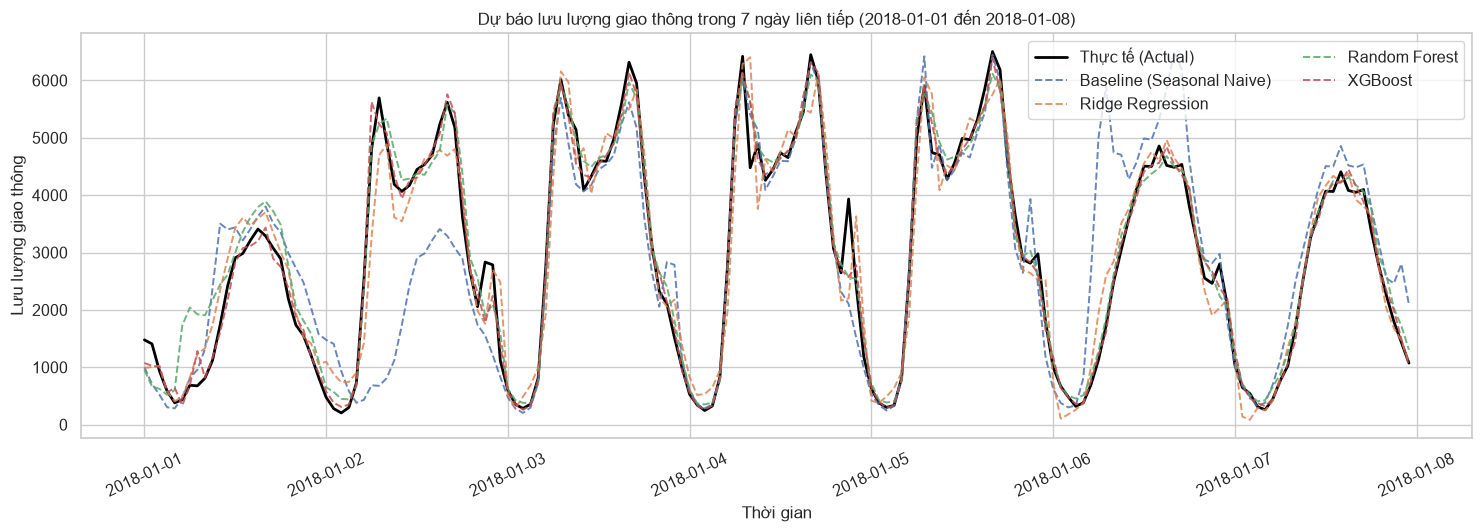

Đã lưu biểu đồ 7 ngày tại: ../figures\note03_forecast_7_days.png


In [14]:
# Yêu cầu df_test có cột thời gian (ví dụ 'date_time' hoặc index dạng DatetimeIndex)
TIME_COL = "date_time"  # Đổi tên nếu cột thời gian của bạn tên khác

plot_df = pd.DataFrame({"actual": np.asarray(y_test, dtype=float)})
if TIME_COL in df_test.columns:
    plot_df["dt"] = pd.to_datetime(df_test[TIME_COL].values)
elif isinstance(df_test.index, pd.DatetimeIndex):
    plot_df["dt"] = df_test.index
else:
    raise ValueError("Không tìm thấy cột thời gian kiểu datetime trong df_test.")

for name, pred in predictions_dict.items():
    plot_df[name] = np.asarray(pred, dtype=float)

plot_df = plot_df.sort_values("dt").reset_index(drop=True)

# Lọc đúng 7 ngày liên tiếp đầu tiên của tập Test
start_dt = plot_df["dt"].iloc[0]
end_dt = start_dt + pd.Timedelta(days=7)
df_7d = plot_df[(plot_df["dt"] >= start_dt) & (plot_df["dt"] < end_dt)]

plt.figure(figsize=(15, 5.5))
plt.plot(df_7d["dt"], df_7d["actual"], label="Thực tế (Actual)", color="black", linewidth=2.0)

for name in predictions_dict.keys():
    plt.plot(df_7d["dt"], df_7d[name], label=name, linestyle="--", linewidth=1.4, alpha=0.85)

plt.title(f"Dự báo lưu lượng giao thông trong 7 ngày liên tiếp ({start_dt.strftime('%Y-%m-%d')} đến {end_dt.strftime('%Y-%m-%d')})")
plt.xlabel("Thời gian")
plt.ylabel("Lưu lượng giao thông")
plt.legend(loc="upper right", ncol=2)
plt.xticks(rotation=25)
plt.tight_layout()

fig_7d_path = os.path.join(FIGURES_DIR, "note03_forecast_7_days.png")
plt.savefig(fig_7d_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ 7 ngày tại: {fig_7d_path}")

C:\Users\T14 GEN2\AppData\Local\Temp\ipykernel_25452\645482756.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weather_err, x="mae", y="weather_group", palette="coolwarm", ax=axes[1])


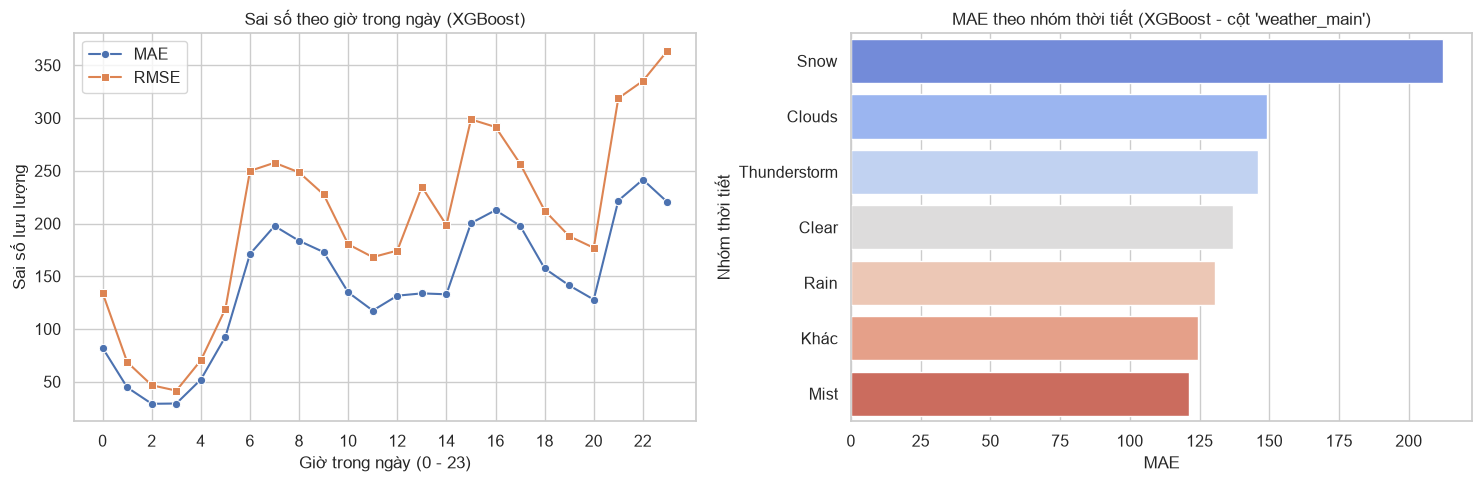

Đã lưu biểu đồ phân tích sai số tại: ../figures\note03_error_analysis_hour_weather.png


,hour,count,mae,rmse,mean_actual
0,0,273,81.98,134.06,830.62
1,1,273,44.61,68.55,505.97
2,2,256,29.09,46.66,379.21
3,3,260,29.36,41.58,371.36
4,4,261,52.12,70.35,738.36
5,5,261,92.78,119.26,2227.72
6,6,269,171.08,249.89,4173.33
7,7,269,197.66,257.61,4820.87
8,8,270,183.60,248.48,4631.07
9,9,270,172.91,227.55,4434.37


,weather_group,count,mae,rmse
5,Snow,449,212.12,305.99
1,Clouds,1983,149.04,226.34
6,Thunderstorm,140,146.01,202.93
0,Clear,2306,136.88,219.57
4,Rain,854,130.61,186.97
2,Khác,224,124.45,203.23
3,Mist,524,121.29,190.29


In [15]:
# Chọn mô hình tốt nhất (RMSE thấp nhất) để phân tích chi tiết sai số
best_model_name = eval_df.loc[0, "Model"]
best_pred = np.asarray(predictions_dict[best_model_name], dtype=float)
y_true_arr = np.asarray(y_test, dtype=float)

err_df = df_test.copy().reset_index(drop=True)
err_df["actual"] = y_true_arr
err_df["pred"] = best_pred
err_df["abs_error"] = np.abs(y_true_arr - best_pred)
err_df["sq_error"] = (y_true_arr - best_pred) ** 2

# Đảm bảo có cột 'hour'
if "hour" not in err_df.columns:
    if TIME_COL in err_df.columns:
        err_df["hour"] = pd.to_datetime(err_df[TIME_COL]).dt.hour
    elif isinstance(df_test.index, pd.DatetimeIndex):
        err_df["hour"] = df_test.index.hour

# 1. Sai số trung bình (MAE & RMSE) theo giờ trong ngày
hourly_err = (
    err_df.groupby("hour", as_index=False)
    .agg(
        count=("abs_error", "size"),
        mae=("abs_error", "mean"),
        rmse=("sq_error", lambda s: float(np.sqrt(np.mean(s)))),
        mean_actual=("actual", "mean"),
    )
)

# 2. Sai số theo điều kiện thời tiết
# Tự động nhận diện cột mô tả thời tiết hoặc mưa/nhiệt độ
weather_col = None
for candidate in ["weather_main", "weather_description", "weather", "rain_1h", "clouds_all", "temp_c"]:
    if candidate in err_df.columns:
        weather_col = candidate
        break

if weather_col is not None:
    if pd.api.types.is_numeric_dtype(err_df[weather_col]):
        # Nếu là cột số (vd: rain_1h, temp_c, clouds_all), chia thành các nhóm khoảng
        err_df["weather_group"] = pd.qcut(
            err_df[weather_col].rank(method="first"),
            q=4,
            labels=["Q1 (Thấp nhất)", "Q2", "Q3", "Q4 (Cao nhất)"],
        )
    else:
        top_cats = err_df[weather_col].value_counts().nlargest(6).index
        err_df["weather_group"] = np.where(
            err_df[weather_col].isin(top_cats), err_df[weather_col], "Khác"
        )

    weather_err = (
        err_df.groupby("weather_group", observed=False, as_index=False)
        .agg(
            count=("abs_error", "size"),
            mae=("abs_error", "mean"),
            rmse=("sq_error", lambda s: float(np.sqrt(np.mean(s)))),
        )
        .sort_values("mae", ascending=False)
    )
else:
    weather_err = None

# Vẽ biểu đồ phân tích sai số
fig, axes = plt.subplots(1, 2 if weather_err is not None else 1, figsize=(15, 5))
if weather_err is None:
    axes = [axes]

sns.lineplot(data=hourly_err, x="hour", y="mae", marker="o", label="MAE", ax=axes[0])
sns.lineplot(data=hourly_err, x="hour", y="rmse", marker="s", label="RMSE", ax=axes[0])
axes[0].set_title(f"Sai số theo giờ trong ngày ({best_model_name})")
axes[0].set_xlabel("Giờ trong ngày (0 - 23)")
axes[0].set_ylabel("Sai số lưu lượng")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()

if weather_err is not None:
    sns.barplot(data=weather_err, x="mae", y="weather_group", palette="coolwarm", ax=axes[1])
    axes[1].set_title(f"MAE theo nhóm thời tiết ({best_model_name} - cột '{weather_col}')")
    axes[1].set_xlabel("MAE")
    axes[1].set_ylabel("Nhóm thời tiết")

plt.tight_layout()
fig_err_path = os.path.join(FIGURES_DIR, "note03_error_analysis_hour_weather.png")
plt.savefig(fig_err_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ phân tích sai số tại: {fig_err_path}")

display(hourly_err.round(2))
if weather_err is not None:
    display(weather_err.round(2))

In [16]:
# Yêu cầu có sẵn trained_models_dict: dict ánh xạ tên mô hình -> object model đã fit
# Ví dụ: trained_models_dict = {"Ridge": ridge_model, "Random Forest": rf_model, "XGBoost": xgb_model}

if best_model_name in trained_models_dict:
    best_model_obj = trained_models_dict[best_model_name]
    safe_name = best_model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    model_out_path = os.path.join(MODELS_DIR, f"best_model_{safe_name}.joblib")
    joblib.dump(
        {
            "model_name": best_model_name,
            "model": best_model_obj,
            "congestion_threshold": CONGESTION_THRESHOLD,
            "metrics": eval_df.iloc[0].to_dict(),
        },
        model_out_path,
    )
    print(f"Đã lưu mô hình tốt nhất '{best_model_name}' tại: {model_out_path}")
else:
    print(
        f"Lưu ý: '{best_model_name}' không nằm trong trained_models_dict "
        f"(ví dụ mô hình Baseline thuần rule không có object sklearn/xgboost). "
        f"Hãy kiểm tra lại trained_models_dict nếu muốn lưu file .joblib."
    )

Đã lưu mô hình tốt nhất 'XGBoost' tại: ../models\best_model_xgboost.joblib
